Hệ số chặn (Intercept): [521.03869746]
Hệ số góc (Slope): [[29.99988285]]
Mean Squared Error (MSE): 8111.606286982127
R^2 score: 0.9962523031032056


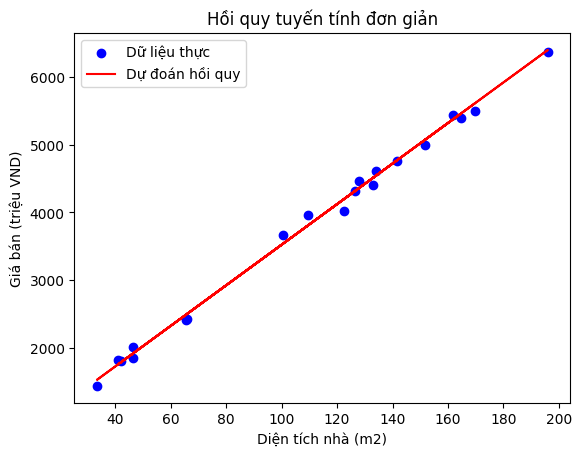

n=50, noise=50: MSE=2689.1, R2=0.998, slope=29.79
n=50, noise=300: MSE=117717.5, R2=0.943, slope=31.43
n=1000, noise=50: MSE=2401.8, R2=0.999, slope=29.94
n=1000, noise=300: MSE=110755.8, R2=0.947, slope=30.07
Hệ số chặn (Intercept): 474.15297456612416
Hệ số hồi quy (Coefficients): [30.07981921 86.21919623 -9.64568532]
Mean Squared Error (MSE): 10288.281900462578
R^2 score: 0.9952958560510716


In [7]:
# ===== THƯ VIỆN CẦN THIẾT (giống ví dụ trong đề cương) =====
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# ---------------------------------------------------------
# 1. HỒI QUY TUYẾN TÍNH ĐƠN GIẢN: Giá bán ~ Diện tích
# ---------------------------------------------------------
np.random.seed(0)  # cố định số ngẫu nhiên để kết quả lặp lại được

# x: Diện tích (m2), sinh ngẫu nhiên từ 30 đến 200 -> shape (100, 1)
x = 30 + 170 * np.random.rand(100, 1)

# y: Giá bán (triệu VND) = 500 + 30*x + nhiễu
# 500 là hệ số chặn, 30 là hệ số góc "thật", np.random.randn là nhiễu chuẩn
y = 500 + 30 * x + 100 * np.random.randn(100, 1)

# Chia 80% huấn luyện / 20% kiểm tra
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2)

model = LinearRegression()        # tạo mô hình
model.fit(x_train, y_train)       # huấn luyện trên tập train
y_pred = model.predict(x_test)    # dự đoán trên tập test

mse = mean_squared_error(y_test, y_pred)  # sai số bình phương trung bình (càng nhỏ càng tốt)
r2 = r2_score(y_test, y_pred)             # độ phù hợp, càng gần 1 càng tốt

print(f"Hệ số chặn (Intercept): {model.intercept_}")  # nên gần 500
print(f"Hệ số góc (Slope): {model.coef_}")            # nên gần 30
print(f"Mean Squared Error (MSE): {mse}")
print(f"R^2 score: {r2}")

plt.scatter(x_test, y_test, color="blue", label="Dữ liệu thực")
plt.plot(x_test, y_pred, color="red", label="Dự đoán hồi quy")
plt.title("Hồi quy tuyến tính đơn giản")
plt.xlabel("Diện tích nhà (m2)")
plt.ylabel("Giá bán (triệu VND)")
plt.legend()
plt.show()

# ---------------------------------------------------------
# 2. THÊM SỐ LƯỢNG DỮ LIỆU VÀ ĐỘ NHIỄU
# ---------------------------------------------------------
# Thử nhiều số mẫu (n) và độ nhiễu (noise) để xem mô hình thay đổi thế nào
for n in [50, 1000]:
    for noise in [50, 300]:
        x = 30 + 170 * np.random.rand(n, 1)
        y = 500 + 30 * x + noise * np.random.randn(n, 1)
        x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
        m = LinearRegression().fit(x_train, y_train)
        p = m.predict(x_test)
        print(f"n={n}, noise={noise}: MSE={mean_squared_error(y_test, p):.1f}, "
              f"R2={r2_score(y_test, p):.3f}, slope={m.coef_[0][0]:.2f}")
# Nhận xét: noise tăng -> MSE tăng, R2 giảm.
#           n tăng -> slope ước lượng ổn định hơn, gần 30 hơn.

# ---------------------------------------------------------
# 3. THÊM BIẾN ĐẦU VÀO (hồi quy đa biến)
# ---------------------------------------------------------
n = 200
dien_tich = 30 + 170 * np.random.rand(n)      # m2
so_phong = np.random.randint(1, 6, n)         # số phòng ngủ
tuoi_nha = np.random.randint(0, 30, n)        # tuổi nhà (năm)

# Giá phụ thuộc cả 3 biến: diện tích tăng giá, phòng tăng giá, nhà cũ giảm giá
gia = 500 + 30*dien_tich + 80*so_phong - 10*tuoi_nha + 100*np.random.randn(n)

# Ghép 3 biến thành ma trận X, mỗi cột là một biến độc lập (shape (200, 3))
X = np.column_stack([dien_tich, so_phong, tuoi_nha])

X_train, X_test, y_train, y_test = train_test_split(X, gia, test_size=0.2, random_state=42)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print(f"Hệ số chặn (Intercept): {model.intercept_}")
print(f"Hệ số hồi quy (Coefficients): {model.coef_}")  # nên gần [30, 80, -10]
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred)}")
print(f"R^2 score: {r2_score(y_test, y_pred)}")

BMI 5 mẫu đầu: [28.3 27.6 21.3 27.1 27.1]
Xác suất mắc bệnh: [0.73  0.659 0.071 0.592 0.595]
Nhãn dự đoán: [1 1 0 1 1]
Độ chính xác (Accuracy): 0.7666666666666667
Ma trận nhầm lẫn (Confusion Matrix):
[[29  8]
 [ 6 17]]


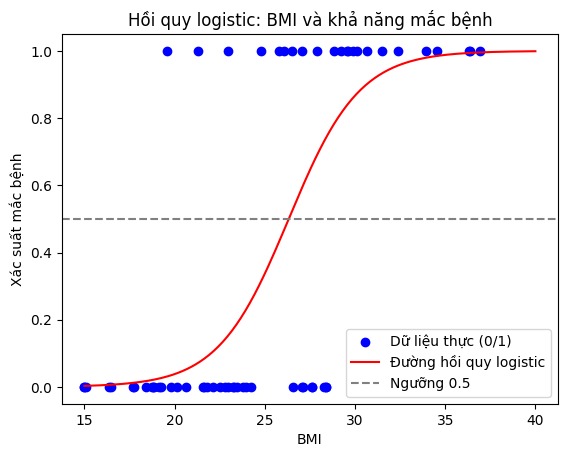

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(0)

# ---------------------------------------------------------
# 1. Tạo dữ liệu giả lập: BMI cao -> khả năng mắc bệnh cao
# ---------------------------------------------------------
n = 300
bmi = np.random.normal(25, 5, n)          # BMI trung bình 25, độ lệch 5
bmi = np.clip(bmi, 15, 40)                # giới hạn BMI trong khoảng hợp lý

# Xác suất mắc bệnh theo hàm sigmoid: BMI càng lớn hơn 27 thì xác suất càng gần 1
xac_suat = 1 / (1 + np.exp(-(bmi - 27) * 0.5))

# Sinh nhãn 0/1: lấy số ngẫu nhiên, nếu nhỏ hơn xác suất thì mắc bệnh (1)
mac_benh = (np.random.rand(n) < xac_suat).astype(int)

X = bmi.reshape(-1, 1)   # sklearn yêu cầu X là ma trận 2 chiều (n, 1)
y = mac_benh

# ---------------------------------------------------------
# 2 + 3. Xây dựng và huấn luyện mô hình
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

# ---------------------------------------------------------
# 4. Dự đoán xác suất và nhãn trên tập kiểm tra
# ---------------------------------------------------------
y_proba = model.predict_proba(X_test)[:, 1]  # cột 1 = xác suất thuộc lớp 1 (mắc bệnh)
y_pred = model.predict(X_test)               # nhãn dự đoán (mặc định ngưỡng 0.5)

print("BMI 5 mẫu đầu:", X_test[:5].ravel().round(1))
print("Xác suất mắc bệnh:", y_proba[:5].round(3))
print("Nhãn dự đoán:", y_pred[:5])

# ---------------------------------------------------------
# 5. Đánh giá: độ chính xác và ma trận nhầm lẫn
# ---------------------------------------------------------
print(f"Độ chính xác (Accuracy): {accuracy_score(y_test, y_pred)}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))
# Cách đọc: [[TN, FP],
#            [FN, TP]]
# TN: đoán không bệnh, thật không bệnh | FP: đoán bệnh, thật không bệnh
# FN: đoán không bệnh, thật có bệnh    | TP: đoán bệnh, thật có bệnh

# ---------------------------------------------------------
# 6. Trực quan hóa dữ liệu và đường hồi quy logistic
# ---------------------------------------------------------
bmi_range = np.linspace(15, 40, 200).reshape(-1, 1)    # dãy BMI liên tục để vẽ đường cong
p_curve = model.predict_proba(bmi_range)[:, 1]         # xác suất tương ứng

plt.scatter(X_test, y_test, color="blue", label="Dữ liệu thực (0/1)")
plt.plot(bmi_range, p_curve, color="red", label="Đường hồi quy logistic")
plt.axhline(0.5, color="gray", linestyle="--", label="Ngưỡng 0.5")
plt.title("Hồi quy logistic: BMI và khả năng mắc bệnh")
plt.xlabel("BMI")
plt.ylabel("Xác suất mắc bệnh")
plt.legend()
plt.show()

Kích thước: (442, 11)
Số giá trị thiếu mỗi cột:
 age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.267807e-01   
25%   -3.729927e-02 -4.464164e-02 -3.422907e-02 -3.665608e-02 -3.424784e-02   
50%    5.383060e-03 -4.464164e-02 -7.283766e-03 -5.670422e-03 -4.320866e-03   
75%    3.807591e-02  5.068012e-02  3.124802e-02  3.564379e-02  2.835801e-02   
max    1.107267e-01  5.068012e-02  1.705552e-01  1.320436e-01  1.539137e-01   

                 s2            s3            s4            s5            s6  \
count  4.420000

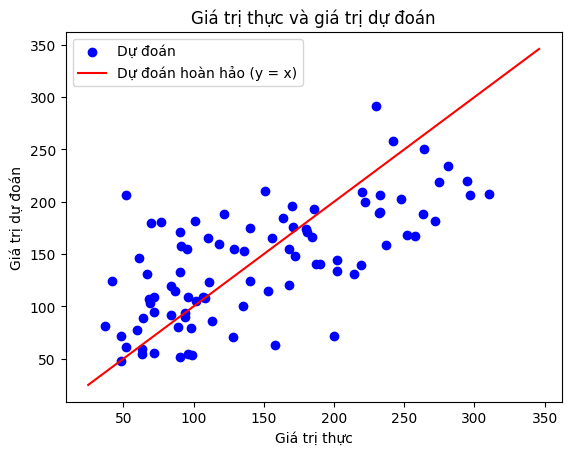

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# ---------------------------------------------------------
# B1. Xác định bài toán: đầu ra "target" là số liên tục -> bài toán HỒI QUY
# ---------------------------------------------------------
data = load_diabetes(as_frame=True)
df = data.frame            # DataFrame gồm 10 cột đặc trưng + cột target

# ---------------------------------------------------------
# B2. Đánh giá thực trạng bộ dữ liệu
# ---------------------------------------------------------
print("Kích thước:", df.shape)
print("Số giá trị thiếu mỗi cột:\n", df.isnull().sum())  # nếu toàn 0 thì không cần xử lý thiếu
print(df.describe())                                     # thống kê mô tả
print(df.corr()["target"].sort_values(ascending=False))  # biến nào tương quan mạnh với target

# ---------------------------------------------------------
# B3. Tiền xử lý
# ---------------------------------------------------------
# Bộ này đã được chuẩn hóa sẵn và không thiếu dữ liệu nên không cần xử lý thêm.
X = df.drop(columns="target")   # các biến đầu vào
y = df["target"]                # biến đầu ra

# ---------------------------------------------------------
# B4. Chia dữ liệu 80% train / 20% test
# ---------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------------------------------
# B5. Huấn luyện mô hình hồi quy tuyến tính đa biến
# ---------------------------------------------------------
model = LinearRegression()
model.fit(X_train, y_train)

# ---------------------------------------------------------
# B6. Dự đoán và đánh giá bằng MSE, R2
# ---------------------------------------------------------
y_pred = model.predict(X_test)
print(f"Hệ số chặn (Intercept): {model.intercept_}")
print("Hệ số hồi quy (Coefficients):")
print(pd.Series(model.coef_, index=X.columns))
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred)}")
print(f"R^2 score: {r2_score(y_test, y_pred)}")  # khoảng 0.45 là bình thường với bộ này

# ---------------------------------------------------------
# B7. Biểu đồ giá trị thực và giá trị dự đoán
# ---------------------------------------------------------
plt.scatter(y_test, y_pred, color="blue", label="Dự đoán")
plt.plot([y.min(), y.max()], [y.min(), y.max()], color="red", label="Dự đoán hoàn hảo (y = x)")
plt.title("Giá trị thực và giá trị dự đoán")
plt.xlabel("Giá trị thực")
plt.ylabel("Giá trị dự đoán")
plt.legend()
plt.show()